# 02 — Pre-processing for the MLP and the CNN (CirCor DigiScope)

Turns the recordings into fixed-size inputs for the two models, with the decisions justified in `01_eda.ipynb`.
The code is in `src/features.py` (configuration and extraction), `src/prepare_data.py` (runs everything and saves to `data/processed/`)
and `src/datasets.py` (loading, per-fold normalisation and per-patient aggregation).

1. Pre-processing decisions
2. Generate the processed data
3. From the signal to the model inputs
4. Do the MLP features separate the classes?
5. Split, imbalance and how to use the data in the models

Pipeline: `01_eda` → **`02_preprocessing`** → `03_mlp` / `04_cnn`.

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

from src.data import load_split, WAV_DIR, CLASSES
from src import features as F

pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Present': '#d62728', 'Unknown': '#7f7f7f', 'Absent': '#1f77b4'}
FIG_DIR = Path('../results/preprocessing'); FIG_DIR.mkdir(parents=True, exist_ok=True)
save = lambda name: plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Pre-processing decisions

| step | choice |
|---|---|
| input | **only the phonocardiogram (`.wav`)**; no demographic or clinical columns |
| sample rate | **native 4 kHz** (no resampling) |
| filtering | **25–1000 Hz band-pass** (4th-order Butterworth, zero phase) |
| amplitude | **z-score per recording** (volumes vary a lot between recordings and stethoscopes) |
| duration | **4 s windows, 2 s hop**; the last < 2 s of each recording are dropped |
| label | **`rec_label`** per recording (from `Murmur locations`) |
| MLP input | **99 features per window**: 20 MFCC (mean, std, std Δ, std ΔΔ) + 6 spectral descriptors (mean, std) + energy in 5 bands + envelope periodicity |
| CNN input | **log-mel 40 × 401** (n_fft 256 = 64 ms, hop 40 = 10 ms, 20–1000 Hz), in dB, no per-window min-max |
| normalisation | **per fold, training folds only**: z-score per feature (MLP) and per mel band (CNN), to avoid data leakage |
| final prediction | windows → recording → **patient** (one prediction per patient) |

The saved data contains no normalisation fitted to the data, so it can be generated once for all folds.

## 2. Generate the processed data
Equivalent to `python -m src.prepare_data`. Only runs if `data/processed/` does not exist yet (or with `FORCE = True`).

| file | content | used by |
|---|---|---|
| `X_mlp.npy` | (n_windows, 99) float32, one feature vector per window | `src/mlp.py`, `03_mlp` |
| `mel.npy` | (40, total_frames) float16, log-mel of every recording concatenated in time | `src/cnn.py`, `04_cnn` (windows sliced on the fly by `CNNWindows`) |
| `windows.csv` | one row per window: recording, patient, location, start, `mel_start`, labels, fold | every model, `src/evaluate.py` (OOF predictions are indexed by its rows) |
| `recordings.csv` | one row per recording, with its position in `mel.npy` | `src/datasets.py` |
| `config.json` | every pre-processing parameter + MLP feature names | `src/datasets.py` |

If these files are regenerated, the saved results in `results/` (`oof.csv`) are only valid if the window order does not change,
so re-train the models after changing any pre-processing parameter.

In [2]:
from src.prepare_data import prepare_data, OUT_DIR
FORCE = False   # True to regenerate (≈ 1–3 min with all cores)
if FORCE or not (OUT_DIR / 'X_mlp.npy').exists():
    prepare_data()
else:
    print('using existing files in', OUT_DIR.resolve())

Dataset: C:\Users\rafa\Documents\FCUP\AC 2\FCUP-DL-ML2\data\the-circor-digiscope-phonocardiogram-dataset-1.0.3
3163 recordings from 942 patients


features: 100%|██████████| 3163/3163 [00:50<00:00, 62.79it/s] 


integrity checks passed

=== SUMMARY ===
MLP input  X_mlp: (31409, 99)  (one vector per window)
CNN input  mel  : (40, 7235810) -> windows of (40, 401)  [579 MB]
windows: 31409  |  per class (rec_label):
rec_label
Absent     24979
Present     4924
Unknown     1506
windows per fold:
fold
-1    6042
 0    5232
 1    5079
 2    4872
 3    5251
 4    4933
saved to C:\Users\rafa\Documents\FCUP\AC 2\FCUP-DL-ML2\data\processed


X_mlp : (31409, 99) float32
mel   : (40, 7235810) float16 579 MB  -> CNN windows of (40, 401)
windows: 31409 | recordings: 3163 | patients: 942


,recording,patient_id,location,start_s,mel_start,murmur,rec_label,fold
0,13918_AV,13918,AV,0.0,0,Present,Absent,4
1,13918_AV,13918,AV,2.0,200,Present,Absent,4
2,13918_AV,13918,AV,4.0,400,Present,Absent,4
3,13918_AV,13918,AV,6.0,600,Present,Absent,4
4,13918_MV,13918,MV,0.0,1029,Present,Absent,4


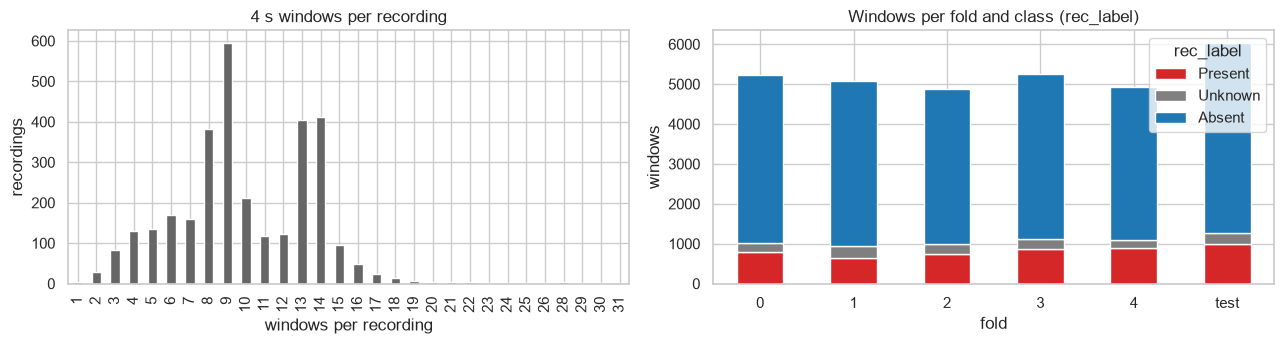

In [3]:
from src.datasets import load_processed, fold_masks, mlp_arrays, mel_band_stats, cnn_arrays, class_weights, aggregate_to_patient
d = load_processed()
print('X_mlp :', d.X_mlp.shape, d.X_mlp.dtype)
print('mel   :', d.mel.shape, d.mel.dtype, f'{d.mel.nbytes / 1e6:.0f} MB  -> CNN windows of', (d.mel.shape[0], d.config['frames_per_window']))
print('windows:', len(d.windows), '| recordings:', len(d.recordings), '| patients:', d.windows.patient_id.nunique())
display(d.windows.head())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
d.recordings.n_windows.value_counts().sort_index().plot.bar(ax=ax[0], color='0.4')
ax[0].set(xlabel='windows per recording', ylabel='recordings', title='4 s windows per recording')
pd.crosstab(d.windows.fold.replace({-1: 'test'}), d.windows.rec_label)[CLASSES].plot.bar(
    stacked=True, ax=ax[1], color=[PALETTE[c] for c in CLASSES], rot=0)
ax[1].set(xlabel='fold', ylabel='windows', title='Windows per fold and class (rec_label)')
plt.tight_layout(); save('windows_per_fold'); plt.show()

## 3. From the signal to the model inputs (one window)

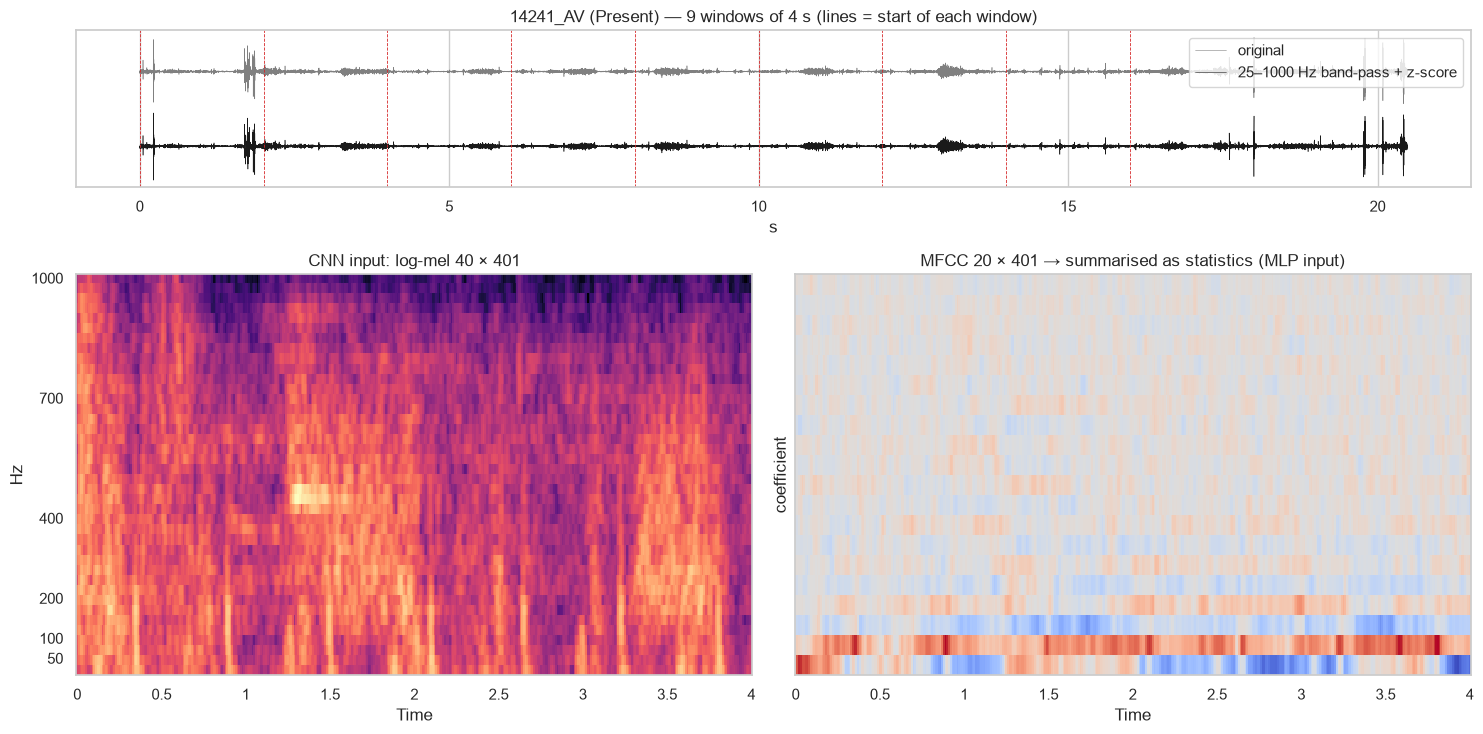

In [4]:
r = d.recordings[(d.recordings.rec_label == 'Present') & (d.recordings.n_windows >= 5)].iloc[0]
path = str(WAV_DIR / f'{r.recording}.wav')
raw, sr = librosa.load(path, sr=None)
y = F.load_audio(path)
wins, starts = F.split_windows(y)
w = wins[1]
mel_w = F.logmel(w)
mfcc_w = librosa.feature.mfcc(y=w, sr=sr, n_mfcc=F.MFCC.n_mfcc, n_fft=F.MFCC.n_fft, hop_length=F.MFCC.hop_length,
                              n_mels=F.MFCC.n_mels, fmin=F.MFCC.fmin, fmax=F.MFCC.fmax)

fig = plt.figure(figsize=(15, 7.5)); gs = fig.add_gridspec(3, 2)
a = fig.add_subplot(gs[0, :]); t = np.arange(len(raw)) / sr
a.plot(t, raw / np.abs(raw).max() + 2.2, lw=.4, color='0.5', label='original')
a.plot(t, y / np.abs(y).max(), lw=.4, color='k', label='25–1000 Hz band-pass + z-score')
for s in starts: a.axvline(s, color='#d62728', lw=.6, ls='--')
a.set(title=f'{r.recording} ({r.rec_label}) — {len(starts)} windows of 4 s (lines = start of each window)', xlabel='s', yticks=[]); a.legend(loc='upper right')
a = fig.add_subplot(gs[1:, 0])
librosa.display.specshow(mel_w, sr=sr, hop_length=F.MEL.hop_length, x_axis='time', y_axis='mel',
                         fmin=F.MEL.fmin, fmax=F.MEL.fmax, ax=a, cmap='magma')
a.set(title=f'CNN input: log-mel {mel_w.shape[0]} × {mel_w.shape[1]}', yticks=[50, 100, 200, 400, 700, 1000])
a = fig.add_subplot(gs[1:, 1])
librosa.display.specshow(mfcc_w, sr=sr, hop_length=F.MFCC.hop_length, x_axis='time', ax=a, cmap='coolwarm')
a.set(title=f'MFCC {mfcc_w.shape[0]} × {mfcc_w.shape[1]} → summarised as statistics (MLP input)', ylabel='coefficient')
plt.tight_layout(); save('features_example'); plt.show()

## 4. Do the MLP features separate the classes?
Before training, we check that the chosen features carry signal: the distribution of some features per class, and a PCA.
We only use the training folds, so as not to look at the test set.

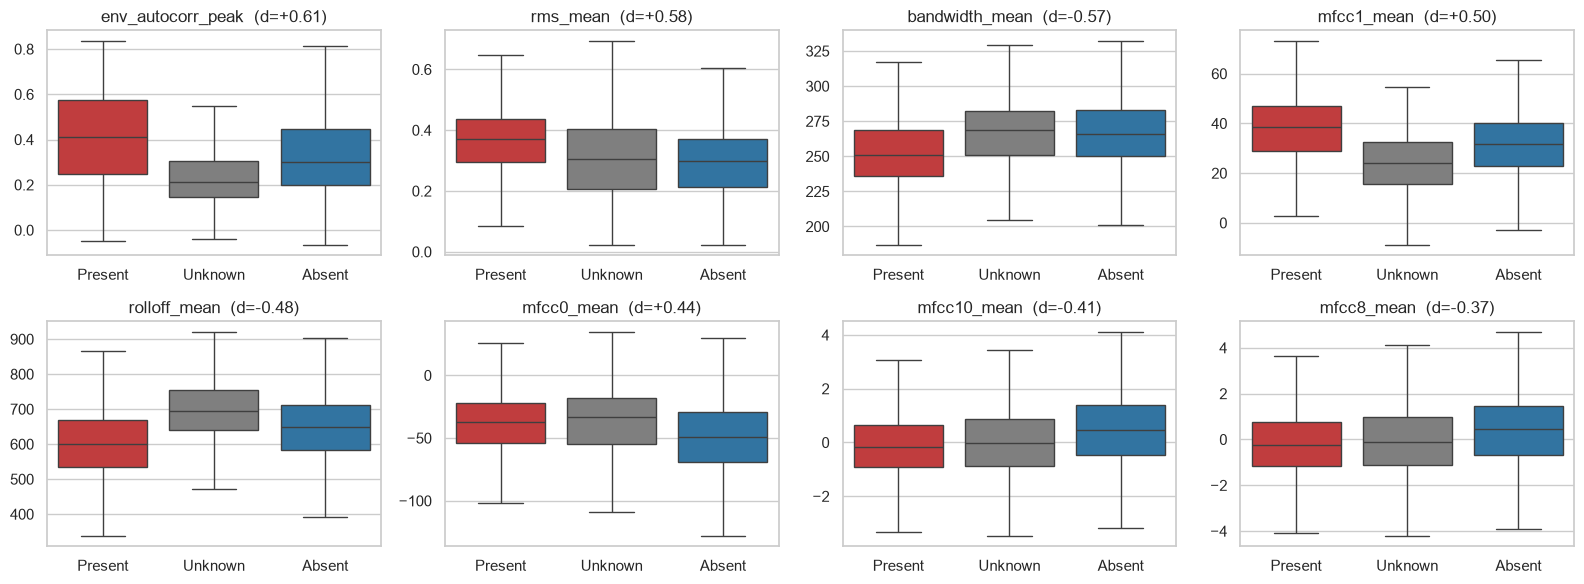

In [5]:
names = d.config['mlp_features']
dev = d.windows.fold >= 0
Xf = pd.DataFrame(d.X_mlp[dev], columns=names); Xf['rec_label'] = d.windows.loc[dev, 'rec_label'].values

# most discriminative features Present vs Absent (difference of medians / standard deviation)
z = (Xf[Xf.rec_label == 'Present'][names].median() - Xf[Xf.rec_label == 'Absent'][names].median()) / Xf[names].std()
top = z.abs().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, top):
    sns.boxplot(x=Xf.rec_label, y=Xf[col], order=CLASSES, palette=PALETTE, ax=ax, showfliers=False)
    ax.set(title=f'{col}  (d={z[col]:+.2f})', xlabel='', ylabel='')
plt.tight_layout(); save('mlp_top_features'); plt.show()

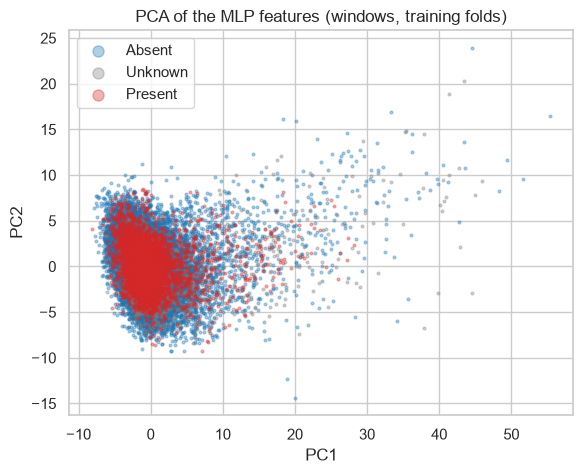

In [6]:
from sklearn.decomposition import PCA
from src.features import Standardizer
Z = PCA(2, random_state=0).fit_transform(Standardizer().fit_transform(d.X_mlp[dev]))
fig, ax = plt.subplots(figsize=(6.5, 5))
for c in ['Absent', 'Unknown', 'Present']:
    m = Xf.rec_label.values == c
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=.35, color=PALETTE[c], label=c)
ax.set(title='PCA of the MLP features (windows, training folds)', xlabel='PC1', ylabel='PC2'); ax.legend(markerscale=4)
save('mlp_pca'); plt.show()

**Reading.** The spectral features and MFCC statistics change consistently between *Present* and *Absent*,
but the classes overlap a lot in the PCA. No single feature solves the problem, so a non-linear model makes sense.
Overlap at window level is also expected: even at a location with a murmur, a noisy window may not show it.
Aggregating several windows and locations per patient compensates for this.

## 5. Split, imbalance and how to use the data in the models

Pipeline: `01_eda` → **`02_preprocessing`** → `03_mlp` / `04_cnn`.

In [7]:
split = load_split()
display(pd.crosstab(split.fold.replace({-1: 'test'}), split.murmur, margins=True)[CLASSES + ['All']])
assert split.groupby('group').fold.nunique().max() == 1   # child from both campaigns in the same fold
assert d.windows.groupby('patient_id').fold.nunique().max() == 1
print('patient/group split: OK')

tr, va, te = fold_masks(d.windows, val_fold=0)
Xtr, ytr, Xva, yva, scaler = mlp_arrays(d, tr, va)
print('\nexample, validation fold 0 -> MLP train', Xtr.shape, '| validation', Xva.shape,
      '| train mean/std after normalisation:', Xtr.mean().round(3), Xtr.std().round(3))
print('class weights (Present, Unknown, Absent):', class_weights(ytr).round(2), '| softened (power=0.5):', class_weights(ytr, power=0.5).round(2))
band = mel_band_stats(d, tr)
Xc, yc = cnn_arrays(d, va, band)
print('CNN validation:', Xc.shape, '(n, channel, mel, frames)')

murmur,Present,Unknown,Absent,All
fold,,,,
0,29,11,111,151
1,28,11,112,151
2,28,11,111,150
3,29,11,111,151
4,29,10,111,150
test,36,14,139,189
All,179,68,695,942


patient/group split: OK

example, validation fold 0 -> MLP train (20135, 99) | validation (5232, 99) | train mean/std after normalisation: -0.0 1.0
class weights (Present, Unknown, Absent): [0.68 2.18 0.13] | softened (power=0.5): [0.93 1.66 0.41]
CNN validation: (5232, 1, 40, 401) (n, channel, mel, frames)


### Summary of the decisions for the models

**Inputs (generated by `python -m src.prepare_data`, in `data/processed/`)**: computed only from the phonocardiograms.
- MLP: `X_mlp.npy`, one vector of 99 features per 4 s window. z-score normalisation with the training mean and std (`mlp_arrays`).
- 2D CNN: log-mel 40 × 401 per window, sliced from `mel.npy` on the fly (`CNNWindows`, or `cnn_arrays` for everything in memory),
  normalised per mel band with training statistics. With `random_crop=True` each epoch sees different crops (*time-shift augmentation*).
  SpecAugment (time/frequency masks) and Gaussian noise can also be added.

**Protocol** (`splits/split.csv`, by patient and stratified)
- 20 % of the patients are held out as test (fold −1), used **only** for the final numbers.
- 5 cross-validation folds on the remaining 80 %, to choose the architecture, early stopping, thresholds and aggregation.

**Imbalance**
- Cross-entropy with class weights (`class_weights`; `power` < 1 softens them, set by `weight_power` in `src/mlp.py` / `src/cnn.py`).
- Decision thresholds tuned on validation to maximise the *weighted accuracy* (see below).

**One prediction per patient** (`src/datasets.aggregate_to_patient` + `src/evaluate.py`)
- Window probabilities are averaged per recording.
- Per patient (`how='max'`, the default): the maximum over recordings of P(Present) and P(Unknown), and the mean of P(Absent).
  One location with a murmur is enough. `03_mlp` / `04_cnn` compare it with `max_present` and `mean` on validation.
- Hierarchical rule, as in the Challenge: *Present* if P(Present) ≥ t_present, otherwise *Unknown* if P(Unknown) ≥ t_unknown, otherwise *Absent*.
  The thresholds are tuned for the weighted accuracy in a nested way: for each fold, on the other four folds (`cv_report`).